# Kalshi favourite-longshot bias: replication, extension and favourite buying

Module 3, hedge fund strategies. Plan: [PLAN.md](PLAN.md).

1. Replicate Bürgi, Deng and Whelan, *Makers and Takers: The Economics of the Kalshi Prediction Market*, on their sample (2021 to April 2025).
2. Extend the same tables out of sample (May 2025 to October 2026).
3. Backtest a weekly favourite-buying portfolio (85–97c), then improve it with a calibration model.

This notebook does the data cleaning and evaluation. The data comes from `download_data.py`, which saves it under `data/`:

```
.venv/bin/python download_data.py
```

The notebook never calls the API, so it runs top to bottom in seconds once the data is on disk.

## 1. Setup

In [1]:
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

In [2]:
DATA = Path("data")
INCLUDE_PAPER_EXTRA = True    # add sports and daily crypto/index markets closing before May 2025 (download_data.py paper-extra)

# --- Sample dates ---
PAPER_START = dt.datetime(2021, 1, 1, tzinfo=dt.timezone.utc)
PAPER_END   = dt.datetime(2025, 5, 1, tzinfo=dt.timezone.utc)    # paper sample ends April 2025
OOS_END     = dt.datetime(2026, 11, 1, tzinfo=dt.timezone.utc)   # out of sample: May 2025 to 31 Oct 2026

# --- Paper sample filters (section 4) ---
MIN_VOLUME_DOLLARS = 1_000
MAX_FINAL_SPREAD = 0.20
MIN_HOURS_OPEN = 24

# --- Strategy (section 7) ---
TAKER_FEE_RATE = 0.07      # fee = 0.07 * p * (1 - p) per contract, rounded up to the cent
INTEREST_RATE = 0.035      # annual interest on cash and positions
FAVOURITE_MIN, FAVOURITE_MAX = 0.85, 0.97
MIN_DAYS_TO_CLOSE, MAX_DAYS_TO_CLOSE = 1, 21
EVENT_CAP = 0.03

## 2. Load data

Three files written by `download_data.py`. Values are stored as text, exactly as the API returned them; section 4 converts them.

- `series.parquet`: every Kalshi series with its category and frequency.
- `markets.parquet`: every settled market in the series we keep (sports, hourly, 15-minute and combo series are left out).
- `candles.parquet`: daily price, bid, ask and volume for markets with at least 1,000 contracts traded that were open at least 24 hours.

The main download skips sports and every series Kalshi tags as hourly or 15-minute. The paper keeps any market open at least 24 hours, which includes sports from January 2025 and the daily markets inside "hourly" crypto and index series (for example KXBTCD and INXU). For the paper period only, `download_data.py paper-extra` adds those markets with their candles and trades under `data/paper_extra/`. Section 4's 24-hour filter keeps the truly hourly markets out.

In [3]:
series = pl.read_parquet(DATA / "series.parquet")
markets = pl.read_parquet(DATA / "markets.parquet")
candles = pl.read_parquet(DATA / "candles.parquet")

extra_tickers = pl.Series("ticker", [], dtype=pl.String)
if INCLUDE_PAPER_EXTRA:
    extra_markets = pl.read_parquet(DATA / "paper_extra" / "markets.parquet")
    extra_tickers = extra_markets["ticker"]
    markets = pl.concat([markets, extra_markets], how="diagonal_relaxed")
    candles = pl.concat([candles, pl.read_parquet(DATA / "paper_extra" / "candles.parquet")], how="diagonal_relaxed")

print(f"{len(series):,} series, {len(markets):,} settled markets, "
      f"{len(candles):,} daily candles for {candles['ticker'].n_unique():,} markets")

16,191 series, 836,960 settled markets, 3,700,181 daily candles for 241,635 markets


Markets with candles, by category and the year they closed.

In [4]:
with_candles = (
    markets
    .filter(pl.col("ticker").is_in(candles["ticker"].unique()))
    .join(series.select(pl.col("ticker").alias("series_ticker"), "category"), on="series_ticker", how="left")
    .with_columns(pl.col("close_time").str.to_datetime(time_zone="UTC").dt.year().alias("year"))
)
(with_candles
 .group_by("category", "year").len()
 .pivot(on="year", index="category", values="len", sort_columns=True)
 .sort("category"))

/var/folders/wm/nxkcxnfx12v9kprllw20m8qh0000gn/T/ipykernel_6459/3187894488.py:3: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  .filter(pl.col("ticker").is_in(candles["ticker"].unique()))


category,2021,2022,2023,2024,2025,2026
str,u32,u32,u32,u32,u32,u32
null,null,null,1171,110,null,null
"""Climate and Weather""",518,2524,2026,5616,13894,54363
"""Commodities""",null,146,123,71,44,15188
"""Companies""",null,null,6,10,39,81
"""Crypto""",null,null,null,5145,3397,1624
…,…,…,…,…,…,…
"""Science and Technology""",13,8,1,103,390,4159
"""Social""",null,null,null,null,38,9
"""Sports""",null,null,null,1,1745,null


## 3. Helper functions

Fee, Mincer-Zarnowitz regression and summary tables. The settlement portfolio and performance statistics come with section 7.

In [5]:
def taker_fee_per_contract(price):
    """Taker fee per contract in dollars, as in the paper: Kalshi charges 0.07 * contracts * p * (1 - p),
    rounded up to the cent on the whole order, and the paper prices an order of 100 contracts."""
    order_fee = (TAKER_FEE_RATE * 100 * price * (1 - price) * 100 - 1e-9).ceil() / 100
    return order_fee / 100


def mean_with_ci(values):
    """Mean and 95% confidence interval as Polars expressions, for group_by().agg()."""
    se = values.std() / values.count().sqrt()
    return [values.mean().alias("mean"), (values.mean() - 1.96 * se).alias("ci_low"),
            (values.mean() + 1.96 * se).alias("ci_high"), values.count().alias("n")]


def mincer_zarnowitz(df, cluster_by=("event_ticker", "ticker")):
    """Paper's equation 3 on Yes contracts, in cents: (100 * Y - price) = a + psi * price.
    Standard errors clustered on the given columns (event and contract by default). Returns one row."""
    data = df.select(
        (100 * pl.col("won").cast(pl.Float64) - 100 * pl.col("price")).alias("profit"),
        (100 * pl.col("price")).alias("price"),
        *cluster_by,
    )
    data = pd.DataFrame({c: data[c].to_numpy() for c in data.columns})     # no pyarrow needed
    groups = np.column_stack([pd.factorize(data[c])[0] for c in cluster_by])
    fit = smf.ols("profit ~ price", data).fit(cov_type="cluster", cov_kwds={"groups": groups if len(cluster_by) > 1 else groups[:, 0]})
    return {"psi": fit.params["price"], "psi_se": fit.bse["price"],
            "constant": fit.params["Intercept"], "constant_se": fit.bse["Intercept"],
            "observations": int(fit.nobs), "F_test_p": float(fit.f_test("Intercept = 0, price = 0").pvalue)}

## 4. Paper sample

The paper's filters (section 3.1 of Bürgi, Deng and Whelan):

1. Markets from Kalshi's launch in 2021 through April 2025 (we also keep May 2025 to October 2026 for section 6).
2. Total trading volume at close of at least $1,000. Kalshi reports volume in contracts, each with $1 notional, so this is `volume_fp >= 1,000`.
3. Final bid–ask spread of 20c or less.
4. Open at least 24 hours, which drops the hourly crypto and index markets.

The final spread comes from the last daily candle that ends no later than one hour after the market closes. Later candles show the book after trading stopped, with a bid of 0 and an ask of 1.

In [6]:
categories = series.select(pl.col("ticker").alias("series_ticker"), "category")

markets_clean = (
    markets
    .select("ticker", "event_ticker", "series_ticker", "title", "yes_sub_title", "market_type", "strike_type", "result", "source",
            pl.col("volume_fp").cast(pl.Float64).alias("volume"),
            pl.col("open_time").str.to_datetime(time_zone="UTC").alias("open"),
            pl.col("close_time").str.to_datetime(time_zone="UTC").alias("close"))
    .join(categories, on="series_ticker", how="left")
)

final_quote = (
    candles
    .select("ticker",
            pl.from_epoch(pl.col("end_period_ts").cast(pl.Int64), time_unit="s").dt.replace_time_zone("UTC").alias("candle_end"),
            pl.col("yes_bid_close").cast(pl.Float64).alias("final_bid"),
            pl.col("yes_ask_close").cast(pl.Float64).alias("final_ask"))
    .join(markets_clean.select("ticker", "close"), on="ticker")
    .filter(pl.col("candle_end") <= pl.col("close") + pl.duration(hours=1))
    .sort("candle_end")
    .group_by("ticker").last()
    .select("ticker", "final_bid", "final_ask", (pl.col("final_ask") - pl.col("final_bid")).alias("final_spread"))
)

In [7]:
sample = (
    markets_clean
    .join(final_quote, on="ticker", how="inner")
    .filter(
        (pl.col("market_type") == "binary")
        & pl.col("result").is_in(["yes", "no"])
        & (pl.col("volume") >= MIN_VOLUME_DOLLARS)
        & (pl.col("final_spread") <= MAX_FINAL_SPREAD)
        & ((pl.col("close") - pl.col("open")) >= pl.duration(hours=MIN_HOURS_OPEN))
        & (pl.col("close") >= PAPER_START) & (pl.col("close") < OOS_END)
    )
    .with_columns(pl.when(pl.col("close") < PAPER_END).then(pl.lit("paper")).otherwise(pl.lit("oos")).alias("period"))
)

sample.group_by("period").agg(
    pl.len().alias("yes_contracts"),
    pl.col("event_ticker").n_unique().alias("events"),
).sort("period", descending=True)

period,yes_contracts,events
str,u32,u32
"""paper""",41739,11678
"""oos""",156916,24732


The paper reports **46,282 Yes contracts and 12,403 events** for 2021 to April 2025. Our counts are lower mainly because sports is left out; the paper notes its results do not change without the sports category.

How many markets each filter removes, for the paper period:

In [8]:
paper_period = markets_clean.filter((pl.col("close") >= PAPER_START) & (pl.col("close") < PAPER_END)).join(final_quote, on="ticker", how="left")
steps = [
    ("settled Yes or No, binary", (pl.col("market_type") == "binary") & pl.col("result").is_in(["yes", "no"])),
    ("volume >= $1,000", pl.col("volume") >= MIN_VOLUME_DOLLARS),
    ("open >= 24 hours", (pl.col("close") - pl.col("open")) >= pl.duration(hours=MIN_HOURS_OPEN)),
    ("final spread <= 20c", pl.col("final_spread") <= MAX_FINAL_SPREAD),
]
rows, keep = [("all settled markets", len(paper_period))], paper_period
for name, condition in steps:
    keep = keep.filter(condition)
    rows.append((name, len(keep)))
pl.DataFrame(rows, schema=["after filter", "markets"], orient="row")

after filter,markets
str,i64
"""all settled markets""",306160
"""settled Yes or No, binary""",306105
"""volume >= $1,000""",79813
"""open >= 24 hours""",53044
"""final spread <= 20c""",41739


Save the sample's tickers so `download_data.py trades` can fetch their trades.

In [9]:
sample.select("ticker", "period").write_parquet(DATA / "trade_tickers.parquet")
print(f"Saved {len(sample):,} tickers to data/trade_tickers.parquet")

Saved 198,655 tickers to data/trade_tickers.parquet


### Price snapshots

The paper takes the last trade before the market closed, then goes back in 24-hour steps to ten days before close. Its footnote 3: if the last trade was at 5:57pm on the closing day, it also records the last trade before 5:57pm on each earlier day that had trades. So each Yes contract has at most 11 prices.

Here the snapshot `k` days before close is the price as of exactly `k` × 24 hours before the last trade: the most recent trade at or before that moment, even if it happened on an earlier day. A contract gets a snapshot for day `k` if it had traded by then. We tested four other readings (24-hour windows, calendar days, same clock time on each calendar day, and windows counted from the market's close time). This one reproduces the paper's Table 1 closely and the others do not.

When one order fills at several prices, all the fills share a timestamp. The order book is swept from the best price outwards, so the last fill is the highest Yes price when the taker bought Yes and the lowest when the taker bought No. Ordering ties this way makes our last trade match Kalshi's reported last price.

Trades are one file per series (`download_data.py trades`). The paper-period files are small enough to load in full.

In [10]:
trade_files = [f for f in sorted((DATA / "trades").glob("*__paper.parquet")) if pl.read_parquet_schema(f)]
if INCLUDE_PAPER_EXTRA:
    trade_files.append(DATA / "paper_extra" / "trades.parquet")
trades = (
    pl.concat([pl.read_parquet(f) for f in trade_files], how="diagonal_relaxed")
    .select("ticker",
            pl.col("created_time").str.to_datetime(time_zone="UTC", format="%Y-%m-%dT%H:%M:%S%.fZ").alias("time"),
            pl.col("yes_price_dollars").cast(pl.Float64).alias("yes_price"),
            pl.col("count_fp").cast(pl.Float64).alias("contracts"),
            pl.col("taker_outcome_side").alias("taker_side"))
)
print(f"{len(trades):,} trades for {trades['ticker'].n_unique():,} markets")

14,164,848 trades for 187,864 markets


In [11]:
last_trade_time = trades.group_by("ticker").agg(pl.col("time").max().alias("last_time"))
sweep_order = pl.when(pl.col("taker_side") == "yes").then(pl.col("yes_price")).otherwise(-pl.col("yes_price"))

snapshot_times = (
    last_trade_time
    .join(pl.DataFrame({"days_before": list(range(11))}, schema={"days_before": pl.Int32}), how="cross")
    .with_columns((pl.col("last_time") - pl.duration(days=1) * pl.col("days_before")).alias("snapshot_time"))
    .sort("snapshot_time")
)
trades_in_order = trades.sort(pl.col("time"), sweep_order).select("ticker", "time", "yes_price", "taker_side")

snapshots = (
    snapshot_times
    .join_asof(trades_in_order, left_on="snapshot_time", right_on="time", by="ticker", strategy="backward")
    .filter(pl.col("time").is_not_null())                      # the contract had not traded yet
    .select("ticker", "days_before", "time", "yes_price", "taker_side")
    .join(sample.select("ticker", "event_ticker", "category", "strike_type", "volume", "result", "close"), on="ticker")
    .sort("ticker", "days_before")
)

/var/folders/wm/nxkcxnfx12v9kprllw20m8qh0000gn/T/ipykernel_6459/2352753295.py:14: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  .join_asof(trades_in_order, left_on="snapshot_time", right_on="time", by="ticker", strategy="backward")


The paper also dropped 63 contracts whose last trade did not match the final price Kalshi reports for the market (footnote 2). We do the same check.

In [12]:
final_price = markets.select("ticker", pl.col("last_price_dollars").cast(pl.Float64).alias("reported_last_price"))
mismatch = (
    snapshots.filter(pl.col("days_before") == 0)
    .join(final_price, on="ticker")
    .filter((pl.col("yes_price") - pl.col("reported_last_price")).abs() > 1e-6)
    ["ticker"]
)
snapshots = snapshots.filter(~pl.col("ticker").is_in(mismatch.implode()))
print(f"Dropped {len(mismatch):,} contracts whose last trade does not match Kalshi's reported last price (paper: 63)")

Dropped 18 contracts whose last trade does not match Kalshi's reported last price (paper: 63)


### Yes and No observations

Each traded Yes price `p` has a matching No price `1 - p` paid by the other side, so every snapshot gives two observations: one for buying Yes and one for buying No.

In [13]:
yes_rows = snapshots.with_columns(pl.lit("yes").alias("side"), pl.col("yes_price").alias("price"),
                                  (pl.col("result") == "yes").alias("won"))
no_rows = snapshots.with_columns(pl.lit("no").alias("side"), (1 - pl.col("yes_price")).round(4).alias("price"),
                                 (pl.col("result") == "no").alias("won"))
observations = pl.concat([yes_rows, no_rows]).drop("yes_price")

print(f"{snapshots['ticker'].n_unique():,} Yes contracts, {snapshots['event_ticker'].n_unique():,} events, "
      f"{len(snapshots):,} Yes prices, {len(observations):,} Yes and No prices")
print(f"Average daily observations per Yes contract: {len(snapshots) / snapshots['ticker'].n_unique():.2f} (paper: 3.5)")

41,721 Yes contracts, 11,678 events, 158,648 Yes prices, 317,296 Yes and No prices
Average daily observations per Yes contract: 3.80 (paper: 3.5)


### Check against the paper

**Headline counts.**

In [14]:
def headline_counts(snaps):
    return [snaps["event_ticker"].n_unique(), snaps["ticker"].n_unique(), len(snaps), 2 * len(snaps)]


pl.DataFrame({
    "count": ["events", "Yes contracts", "Yes prices", "Yes and No prices"],
    "ours": headline_counts(snapshots),
    "main_listing_only": headline_counts(snapshots.filter(~pl.col("ticker").is_in(extra_tickers.implode()))),
    "paper": [12_403, 46_282, 156_986, 313_972],
}).with_columns((pl.col("ours") / pl.col("paper")).round(2).alias("ratio"))

count,ours,main_listing_only,paper,ratio
str,i64,i64,i64,f64
"""events""",11678,9946,12403,0.94
"""Yes contracts""",41721,32837,46282,0.9
"""Yes prices""",158648,141185,156986,1.01
"""Yes and No prices""",317296,282370,313972,1.01


**Table 1: Yes contracts by how far back they have prices.** Each contract is counted by the furthest day before close with a price.

In [15]:
paper_table_1 = [19_338, 12_861, 1_723, 1_083, 1_311, 1_288, 1_461, 159, 150, 154, 6_754]

(snapshots
 .group_by("ticker").agg(pl.col("days_before").max().alias("furthest_day"))
 .group_by("furthest_day").len().sort("furthest_day")
 .with_columns(pl.Series("paper", paper_table_1)))

furthest_day,len,paper
i32,u32,i64
0,13203,19338
1,14116,12861
2,1652,1723
3,1065,1083
4,1207,1311
…,…,…
6,1424,1461
7,164,159
8,152,150


**Table 2: Yes and No observations by price range.** The paper's ranges are symmetric around 50c: a Yes at 41–49c is a No at 51–59c, and 50c is a No at 50c. So "41c-50c" holds 41–49c and "50c-59c" holds 50–59c, which is how the paper's numbers add up to 313,972.

In [16]:
PRICE_RANGES = ["1c-10c", "11c-20c", "21c-30c", "31c-40c", "41c-50c", "50c-59c", "60c-69c", "70c-79c", "80c-89c", "90c-99c"]
paper_table_2 = [106_209, 20_395, 12_558, 10_049, 7_199, 8_351, 10_049, 12_558, 20_395, 106_209]


def price_range(price):
    """The paper's 10c price ranges (Table 2)."""
    cents = (price * 100).round(2)
    return (pl.when(cents <= 10).then(pl.lit("1c-10c"))
            .when(cents <= 20).then(pl.lit("11c-20c"))
            .when(cents <= 30).then(pl.lit("21c-30c"))
            .when(cents <= 40).then(pl.lit("31c-40c"))
            .when(cents < 50).then(pl.lit("41c-50c"))
            .when(cents < 60).then(pl.lit("50c-59c"))
            .when(cents < 70).then(pl.lit("60c-69c"))
            .when(cents < 80).then(pl.lit("70c-79c"))
            .when(cents < 90).then(pl.lit("80c-89c"))
            .otherwise(pl.lit("90c-99c")))


observations = observations.with_columns(price_range(pl.col("price")).alias("price_range"))

table_2 = (
    observations.group_by("price_range").len()
    .join(pl.DataFrame({"price_range": PRICE_RANGES, "paper": paper_table_2, "order": range(10)}), on="price_range")
    .sort("order").drop("order")
    .with_columns((100 * pl.col("len") / pl.col("len").sum()).round(1).alias("percent"),
                  (100 * pl.col("paper") / pl.col("paper").sum()).round(1).alias("paper_percent"))
)
table_2

price_range,len,paper,percent,paper_percent
str,u32,i64,f64,f64
"""1c-10c""",104662,106209,33.0,33.8
"""11c-20c""",20583,20395,6.5,6.5
"""21c-30c""",13581,12558,4.3,4.0
"""31c-40c""",11005,10049,3.5,3.2
"""41c-50c""",8149,7199,2.6,2.3
"""50c-59c""",9485,8351,3.0,2.7
"""60c-69c""",11005,10049,3.5,3.2
"""70c-79c""",13581,12558,4.3,4.0
"""80c-89c""",20583,20395,6.5,6.5


## 5. Replication

Definitions from the paper (sections 3.2 to 4):

- `Y` is 1 if the contract's outcome happened, `P` the price paid in dollars.
- Pre-fee return: `(Y - P) / P`.
- Post-fee return for Takers (equation 2): the commission `C` is added to the cost, so `(Y - P - C) / (P + C)`. Makers paid no fees before May 2025.
- Each Yes snapshot trade had a Taker on one side and a Maker on the other. The observation on the Taker's side (`taker_side`) is the Taker's purchase, the other is the Maker's, so exactly half the observations are each.

In [17]:
paper_obs = (
    observations
    .filter(pl.col("close") < PAPER_END)
    .with_columns(
        (pl.col("side") == pl.col("taker_side")).alias("taker"),
        taker_fee_per_contract(pl.col("price")).alias("fee"),
    )
    .with_columns(
        ((pl.col("won").cast(pl.Float64) - pl.col("price")) / pl.col("price")).alias("return_pre_fee"),
        pl.when(pl.col("taker"))
          .then((pl.col("won").cast(pl.Float64) - pl.col("price") - pl.col("fee")) / (pl.col("price") + pl.col("fee")))
          .otherwise((pl.col("won").cast(pl.Float64) - pl.col("price")) / pl.col("price"))
          .alias("return_post_fee"),
    )
)
print(f"{len(paper_obs):,} Yes and No observations, {paper_obs['taker'].mean():.1%} bought by Takers")

317,296 Yes and No observations, 50.0% bought by Takers


### Average returns

Paper: about **-20%** before fees across all contracts; Takers **-31.46%** and Makers **-9.64%** after fees; Makers buying at 50c or more earn **+2.6%**.

In [18]:
pl.DataFrame({
    "measure": ["all contracts, pre-fee", "all contracts, post-fee", "Takers, post-fee", "Makers", "Makers at 50c and over"],
    "ours": [
        paper_obs["return_pre_fee"].mean(),
        paper_obs["return_post_fee"].mean(),
        paper_obs.filter(pl.col("taker"))["return_post_fee"].mean(),
        paper_obs.filter(~pl.col("taker"))["return_post_fee"].mean(),
        paper_obs.filter(~pl.col("taker") & (pl.col("price") >= 0.50))["return_post_fee"].mean(),
    ],
    "paper": [-0.20, None, -0.3146, -0.0964, 0.026],
}).with_columns(pl.col("ours").round(4))

measure,ours,paper
str,f64,f64
"""all contracts, pre-fee""",-0.1821,-0.2
"""all contracts, post-fee""",-0.1907,null
"""Takers, post-fee""",-0.3251,-0.3146
"""Makers""",-0.0562,-0.0964
"""Makers at 50c and over""",0.0279,0.026


### Win rate by price (Figure 3) and returns by price range (Figure 5)

Paper: contracts at 10c and under lose **over 60%** after fees; small positive returns above 50c, statistically significant above 70c.

In [19]:
order = pl.DataFrame({"price_range": PRICE_RANGES, "order": range(10)})

returns_by_range = (
    paper_obs.group_by("price_range")
    .agg(pl.col("won").mean().alias("win_rate"), pl.col("price").mean().alias("avg_price"),
         pl.col("return_pre_fee").mean().alias("return_pre_fee"),
         *mean_with_ci(pl.col("return_post_fee")))
    .join(order, on="price_range").sort("order").drop("order")
    .rename({"mean": "return_post_fee"})
)
returns_by_range.with_columns(pl.selectors.float().round(3))

price_range,win_rate,avg_price,return_pre_fee,return_post_fee,ci_low,ci_high,n
str,f64,f64,f64,f64,f64,f64,u32
"""1c-10c""",0.018,0.03,-0.525,-0.535,-0.564,-0.506,104662
"""11c-20c""",0.124,0.151,-0.176,-0.198,-0.227,-0.168,20583
"""21c-30c""",0.227,0.253,-0.104,-0.125,-0.152,-0.097,13581
"""31c-40c""",0.344,0.353,-0.026,-0.047,-0.072,-0.022,11005
"""41c-50c""",0.44,0.45,-0.021,-0.039,-0.063,-0.015,8149
"""50c-59c""",0.552,0.543,0.016,0.0,-0.018,0.019,9485
"""60c-69c""",0.656,0.647,0.014,0.003,-0.011,0.017,11005
"""70c-79c""",0.773,0.747,0.034,0.026,0.016,0.035,13581
"""80c-89c""",0.876,0.849,0.032,0.027,0.021,0.032,20583


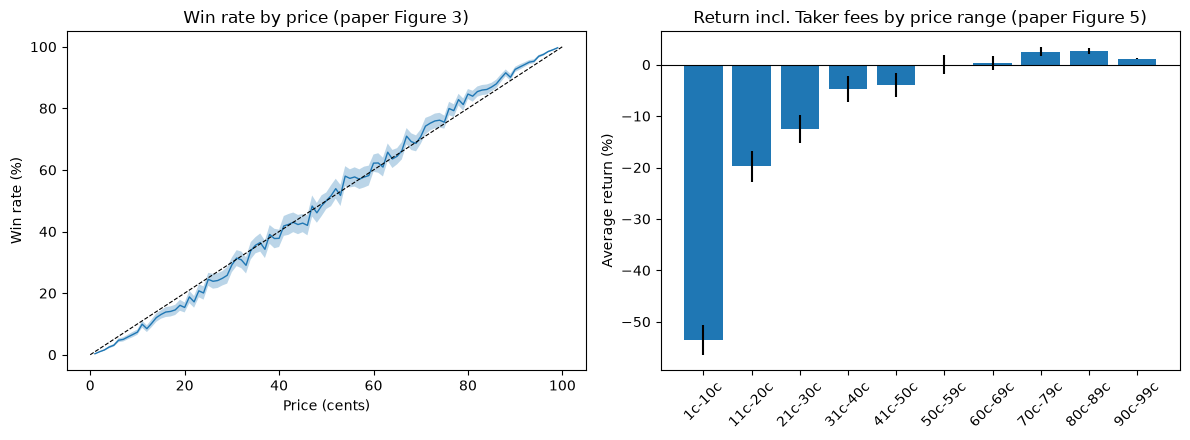

In [20]:
win_by_cent = (paper_obs.with_columns((pl.col("price") * 100).round(0).alias("cents"))
               .group_by("cents").agg(*mean_with_ci(pl.col("won").cast(pl.Float64))).sort("cents"))

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5))
left.fill_between(win_by_cent["cents"], 100 * win_by_cent["ci_low"], 100 * win_by_cent["ci_high"], alpha=0.3)
left.plot(win_by_cent["cents"], 100 * win_by_cent["mean"], lw=1)
left.plot([0, 100], [0, 100], "k--", lw=0.8)
left.set(title="Win rate by price (paper Figure 3)", xlabel="Price (cents)", ylabel="Win rate (%)")

x = range(len(PRICE_RANGES))
right.bar(x, 100 * returns_by_range["return_post_fee"],
          yerr=[100 * (returns_by_range["return_post_fee"] - returns_by_range["ci_low"]),
                100 * (returns_by_range["ci_high"] - returns_by_range["return_post_fee"])])
right.axhline(0, color="k", lw=0.8)
right.set_xticks(list(x), PRICE_RANGES, rotation=45)
right.set(title="Return incl. Taker fees by price range (paper Figure 5)", ylabel="Average return (%)")
plt.tight_layout()

### Makers and Takers (Table 10 and Figure 6)

In [21]:
paper_maker_share = [43.5, 46.7, 48.9, 47.8, 49.5, 50.4, 52.2, 51.1, 53.3, 56.5]

(paper_obs.group_by("price_range")
 .agg(pl.len().alias("total"), (~pl.col("taker")).sum().alias("makers"),
      pl.col("return_post_fee").filter(pl.col("taker")).mean().alias("taker_return"),
      pl.col("return_post_fee").filter(~pl.col("taker")).mean().alias("maker_return"))
 .join(order, on="price_range").sort("order").drop("order")
 .with_columns((100 * pl.col("makers") / pl.col("total")).round(1).alias("maker_share"),
               pl.Series("paper_maker_share", paper_maker_share))
 .with_columns(pl.col("taker_return").round(3), pl.col("maker_return").round(3)))

price_range,total,makers,taker_return,maker_return,maker_share,paper_maker_share
str,u32,u32,f64,f64,f64,f64
"""1c-10c""",104662,44291,-0.746,-0.248,42.3,43.5
"""11c-20c""",20583,9687,-0.327,-0.053,47.1,46.7
"""21c-30c""",13581,6616,-0.241,-0.002,48.7,48.9
"""31c-40c""",11005,5231,-0.112,0.025,47.5,47.8
"""41c-50c""",8149,4025,-0.075,-0.002,49.4,49.5
"""50c-59c""",9485,4792,-0.04,0.04,50.5,50.4
"""60c-69c""",11005,5774,-0.035,0.038,52.5,52.2
"""70c-79c""",13581,6965,-0.016,0.065,51.3,51.1
"""80c-89c""",20583,10896,-0.002,0.052,52.9,53.3


### Mincer-Zarnowitz regressions (Tables 4, 5, 8 and 9)

`(100Y - P) = a + psi * P` on the Yes contracts only, prices in cents, standard errors clustered by event and contract. A negative constant with a positive `psi` is the favourite-longshot pattern; the paper rejects `a = psi = 0` in every sample.

In [22]:
yes_obs = paper_obs.filter(pl.col("side") == "yes")
pl.DataFrame([{"sample": "all (Table 4, col 1)", **mincer_zarnowitz(yes_obs)}]).with_columns(pl.selectors.float().round(3))

sample,psi,psi_se,constant,constant_se,observations,F_test_p
str,f64,f64,f64,f64,i64,f64
"""all (Table 4, col 1)""",0.031,0.005,-1.62,0.161,158648,0.0


Paper Table 4, column 1: psi **0.034** (0.005), constant **-1.736** (0.153), 156,986 observations.

**By days before close (Table 5)**, clustered by event as in the paper:

In [23]:
paper_table_5_psi = [0.036, 0.017, 0.041, 0.036, 0.032, 0.029, 0.021, 0.037, 0.035, 0.040, 0.038]
pl.DataFrame([{"days_before": k, **mincer_zarnowitz(yes_obs.filter(pl.col("days_before") == k), cluster_by=("event_ticker",))}
              for k in range(11)]).with_columns(pl.Series("paper_psi", paper_table_5_psi), pl.selectors.float().round(3))

days_before,psi,psi_se,constant,constant_se,observations,F_test_p,paper_psi
i64,f64,f64,f64,f64,i64,f64,f64
0,0.033,0.001,-2.03,0.06,41721,0.0,0.036
1,0.011,0.006,-1.091,0.176,28518,0.0,0.017
2,0.036,0.007,-1.805,0.23,14402,0.0,0.041
3,0.035,0.008,-1.546,0.276,12750,0.0,0.036
4,0.03,0.008,-1.257,0.302,11685,0.0,0.032
…,…,…,…,…,…,…,…
6,0.021,0.009,-1.243,0.343,9144,0.0,0.021
7,0.038,0.009,-1.444,0.354,7720,0.0,0.037
8,0.036,0.009,-1.484,0.363,7556,0.0,0.035


**By category (Table 8).** The paper's groups: Financials, Climate & Weather, Crypto, Politics, Entertainment, Economics and Other. We count Kalshi's Elections category as Politics and put the remaining categories in Other.

In [24]:
PAPER_CATEGORY = {"Financials": "Financials", "Climate and Weather": "Climate & Weather", "Crypto": "Crypto",
                  "Politics": "Politics", "Elections": "Politics", "Entertainment": "Entertainment", "Economics": "Economics"}
paper_table_8 = {"Financials": 0.032, "Climate & Weather": 0.031, "Crypto": 0.058, "Politics": 0.022,
                 "Entertainment": 0.020, "Economics": 0.034, "Other": 0.053}

yes_obs = yes_obs.with_columns(pl.col("category").replace_strict(PAPER_CATEGORY, default="Other").alias("paper_category"))
pl.DataFrame([{"category": c, **mincer_zarnowitz(yes_obs.filter(pl.col("paper_category") == c)), "paper_psi": paper_table_8[c]}
              for c in paper_table_8]).with_columns(pl.selectors.float().round(3))

category,psi,psi_se,constant,constant_se,observations,F_test_p,paper_psi
str,f64,f64,f64,f64,i64,f64,f64
"""Financials""",0.021,0.015,-1.321,0.266,17955,0.0,0.032
"""Climate & Weather""",0.029,0.005,-0.907,0.235,31861,0.0,0.031
"""Crypto""",0.054,0.014,-1.841,0.821,8795,0.0,0.058
"""Politics""",0.028,0.021,-1.869,0.328,26473,0.0,0.022
"""Entertainment""",0.023,0.011,-2.507,0.358,27514,0.0,0.02
"""Economics""",0.03,0.009,-1.168,0.9,27959,0.006,0.034
"""Other""",0.041,0.009,-1.904,0.382,18091,0.0,0.053


**By year of market close (Table 9).** The paper finds the bias weaker in 2025.

In [25]:
paper_table_9 = {2021: 0.041, 2022: 0.023, 2023: 0.036, 2024: 0.048, 2025: 0.021}
yes_obs = yes_obs.with_columns(pl.col("close").dt.year().alias("year"))
pl.DataFrame([{"year": y, **mincer_zarnowitz(yes_obs.filter(pl.col("year") == y)), "paper_psi": paper_table_9[y]}
              for y in paper_table_9]).with_columns(pl.selectors.float().round(3))

year,psi,psi_se,constant,constant_se,observations,F_test_p,paper_psi
i64,f64,f64,f64,f64,i64,f64,f64
2021,0.037,0.015,-1.554,1.219,3811,0.053,0.041
2022,0.017,0.011,-1.402,0.447,22531,0.002,0.023
2023,0.037,0.01,-1.491,0.412,21221,0.0,0.036
2024,0.045,0.007,-1.69,0.32,49103,0.0,0.048
2025,0.022,0.009,-1.691,0.235,61982,0.0,0.021


**Average post-fee return by category and year.**

In [26]:
paper_obs = paper_obs.with_columns(pl.col("category").replace_strict(PAPER_CATEGORY, default="Other").alias("paper_category"),
                                   pl.col("close").dt.year().alias("year"))
(paper_obs.group_by("paper_category").agg(pl.len().alias("observations"), pl.col("return_post_fee").mean().round(3).alias("return_post_fee"))
 .sort("observations", descending=True))

paper_category,observations,return_post_fee
str,u32,f64
"""Climate & Weather""",63722,-0.193
"""Economics""",55918,-0.14
"""Entertainment""",55028,-0.186
"""Politics""",52946,-0.245
"""Other""",36182,-0.204
"""Financials""",35910,-0.194
"""Crypto""",17590,-0.165


In [27]:
(paper_obs.group_by("year").agg(pl.len().alias("observations"), pl.col("return_pre_fee").mean().round(3).alias("return_pre_fee"),
                                pl.col("return_post_fee").mean().round(3).alias("return_post_fee"))
 .sort("year"))

year,observations,return_pre_fee,return_post_fee
i32,u32,f64,f64
2021,7622,-0.079,-0.092
2022,45062,-0.134,-0.145
2023,42442,-0.167,-0.177
2024,98206,-0.19,-0.197
2025,123964,-0.205,-0.213


### Contract types, volume and trade size (Tables 4, 6 and 7)

**Table 4** splits markets by type, using each event's `mutually_exclusive` flag from `download_data.py events`:

- **Single**: the event has one contract.
- **Non-exclusive**: several contracts that can all win (e.g. CPI above 0.2%, above 0.3%).
- **Exclusive numerical**: only one can win and the contract is a numerical range (Kalshi `strike_type` greater, less or between).
- **Exclusive other**: only one can win, anything else (e.g. who wins an Oscar).

In [28]:
events = pl.read_parquet(DATA / "events.parquet").select("event_ticker", (pl.col("mutually_exclusive") == "True").alias("mutually_exclusive"))
contracts_per_event = markets.group_by("event_ticker").agg(pl.col("ticker").n_unique().alias("contracts_in_event"))
NUMERICAL_STRIKES = ["greater", "greater_or_equal", "less", "less_or_equal", "between"]

yes_obs = (
    yes_obs.join(events, on="event_ticker", how="left").join(contracts_per_event, on="event_ticker", how="left")
    .with_columns(
        pl.when(pl.col("contracts_in_event") == 1).then(pl.lit("Single"))
          .when(~pl.col("mutually_exclusive")).then(pl.lit("Non-exclusive"))
          .when(pl.col("strike_type").is_in(NUMERICAL_STRIKES)).then(pl.lit("Exclusive numerical"))
          .otherwise(pl.lit("Exclusive other")).alias("contract_type"))
)

paper_table_4 = {"Single": (0.045, 16_433), "Non-exclusive": (0.036, 58_602),
                 "Exclusive numerical": (0.014, 46_674), "Exclusive other": (0.020, 35_277)}
rows = []
for kind, (paper_psi, paper_n) in paper_table_4.items():
    subset = yes_obs.filter(pl.col("contract_type") == kind)
    cluster = ("ticker",) if kind == "Single" else ("event_ticker", "ticker")      # as in the paper's notes
    rows.append({"contract_type": kind, **mincer_zarnowitz(subset, cluster_by=cluster),
                 "paper_psi": paper_psi, "paper_observations": paper_n})
rows.append({"contract_type": "All exclusive", **mincer_zarnowitz(yes_obs.filter(pl.col("contract_type").str.starts_with("Exclusive"))),
             "paper_psi": 0.017, "paper_observations": 81_951})
pl.DataFrame(rows).with_columns(pl.selectors.float().round(3))

contract_type,psi,psi_se,constant,constant_se,observations,F_test_p,paper_psi,paper_observations
str,f64,f64,f64,f64,i64,f64,f64,i64
"""Single""",0.04,0.012,0.117,0.799,11249,0.001,0.045,16433
"""Non-exclusive""",0.033,0.007,-1.598,0.489,64322,0.0,0.036,58602
"""Exclusive numerical""",0.001,0.005,-2.049,0.125,44618,0.0,0.014,46674
"""Exclusive other""",0.025,0.007,-1.203,0.209,38459,0.0,0.02,35277
"""All exclusive""",0.016,0.005,-1.71,0.112,83077,0.0,0.017,81951


**Table 6: by final volume quintile**, closing prices only, clustered by event. Quintile 1 has the lowest total volume.

In [29]:
closing = yes_obs.filter(pl.col("days_before") == 0)
closing = closing.with_columns((pl.col("volume").rank("ordinal") * 5 / (pl.len() + 1)).floor().cast(pl.Int32).add(1).alias("volume_quintile"))

paper_table_6 = [0.045, 0.039, 0.032, 0.036, 0.032]
pl.DataFrame([{"volume_quintile": q, **mincer_zarnowitz(closing.filter(pl.col("volume_quintile") == q), cluster_by=("event_ticker",)),
               "paper_psi": paper_table_6[q - 1]} for q in range(1, 6)]).with_columns(pl.selectors.float().round(3))

volume_quintile,psi,psi_se,constant,constant_se,observations,F_test_p,paper_psi
i64,f64,f64,f64,f64,i64,f64,f64
1,0.045,0.003,-2.496,0.133,8344,0.0,0.045
2,0.034,0.003,-2.294,0.128,8344,0.0,0.039
3,0.029,0.003,-2.152,0.133,8345,0.0,0.032
4,0.031,0.003,-1.637,0.12,8344,0.0,0.036
5,0.027,0.002,-1.543,0.106,8344,0.0,0.032


**Table 7: by average trade size quintile**, closing prices only. Trade size is the dollars the Taker paid per trade (contracts times the Taker's price), averaged over all of the contract's trades. The paper reports a mean trade of \$100 and a median of \$35.

In [30]:
trade_size = (
    trades
    .with_columns((pl.col("contracts") * pl.when(pl.col("taker_side") == "yes").then(pl.col("yes_price")).otherwise(1 - pl.col("yes_price"))).alias("dollars"))
)
print(f"Trade size: mean ${trade_size['dollars'].mean():.0f}, median ${trade_size['dollars'].median():.0f} (paper: $100 and $35)")

closing = (closing.join(trade_size.group_by("ticker").agg(pl.col("dollars").mean().alias("mean_trade_size")), on="ticker")
           .with_columns((pl.col("mean_trade_size").rank("ordinal") * 5 / (pl.len() + 1)).floor().cast(pl.Int32).add(1).alias("size_quintile")))

paper_table_7 = [0.036, 0.033, 0.038, 0.034, 0.043]
pl.DataFrame([{"size_quintile": q, **mincer_zarnowitz(closing.filter(pl.col("size_quintile") == q), cluster_by=("event_ticker",)),
               "paper_psi": paper_table_7[q - 1]} for q in range(1, 6)]).with_columns(pl.selectors.float().round(3))

Trade size: mean $110, median $11 (paper: $100 and $35)


size_quintile,psi,psi_se,constant,constant_se,observations,F_test_p,paper_psi
i64,f64,f64,f64,f64,i64,f64,f64
1,0.033,0.003,-1.996,0.109,8344,0.0,0.036
2,0.028,0.003,-2.005,0.12,8344,0.0,0.033
3,0.033,0.003,-1.624,0.12,8345,0.0,0.038
4,0.033,0.003,-1.905,0.129,8344,0.0,0.034
5,0.038,0.003,-2.608,0.143,8344,0.0,0.043


## 6. Out of sample

*To do:* The same tables for May 2025 to October 2026.

## 7. Strategy backtest

*To do:* Weekly favourite buying, 85–97c, 1–21 days to close; NAV, performance and tail statistics.

## 8. Calibration model

*To do:* Logistic regression fit on pre-May-2025 data, reliability check, out-of-sample comparison with section 7.

## 9. Conclusions

*To do:* Findings and judgment.